# Etapa 1. Clustering en el espacio original

## Entorno

Importé las librerías y fijé la semilla 42, que usan la partición y todos los modelos. Sin semilla,
K-Means y GMM arrancan desde centroides o componentes distintos en cada corrida, así que los grupos, su
numeración y las métricas cambiarían, y nadie podría verificar las cifras del informe. También imprimí
las versiones de Python, NumPy, pandas, scikit-learn y Matplotlib, porque los valores por defecto de los
estimadores cambian de una versión a otra y con ellos los resultados.

Definí tres funciones auxiliares. La función redondear aplica redondeo mitad hacia arriba una sola vez
sobre el valor completo. La usé en todas las cifras que se guardan porque round de Python trabaja sobre
la representación binaria y, por ejemplo, redondea 0,2175 a 0,217, mientras que el informe diría 0,218.
Así cada número se ve igual en el notebook y en el informe. La función guardar escribe la figura en
splits antes de mostrarla, porque plt.show libera la figura y el archivo saldría en blanco. La función
guardar_resultados agrega las cifras de cada notebook a resultados.json, de donde las toma el informe sin
copiarlas a mano.

In [1]:
import os, time, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib
from decimal import Decimal, ROUND_HALF_UP

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.dpi'] = 100
SEMILLA = 42
np.random.seed(SEMILLA)

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    if not os.path.isdir('/content/drive/MyDrive'):
        raise RuntimeError('Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso '
                           'en la ventana emergente.')
    RUTA = '/content/drive/MyDrive/credit_card'
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')

CARPETA_SPLITS = os.path.join(RUTA, 'splits')
os.makedirs(CARPETA_SPLITS, exist_ok=True)
ARCHIVO_RESULTADOS = os.path.join(RUTA, 'resultados.json')
resultados = {}
if os.path.exists(ARCHIVO_RESULTADOS):
    with open(ARCHIVO_RESULTADOS, encoding='utf-8') as f:
        resultados = json.load(f)

def redondear(valor, decimales=3):
    r = Decimal(repr(float(valor))).quantize(Decimal(1).scaleb(-decimales), rounding=ROUND_HALF_UP)
    return int(r) if decimales == 0 else float(r)

def redondear_serie(serie, decimales=3):
    return serie.map(lambda v: redondear(v, decimales))

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SPLITS, nombre + '.png'), dpi=150, bbox_inches='tight', facecolor='white')
    print('Gráfico guardado:', nombre + '.png')
    plt.show()

def guardar_resultados():
    with open(ARCHIVO_RESULTADOS, 'w', encoding='utf-8') as f:
        json.dump(resultados, f, ensure_ascii=False, indent=1,
                  default=lambda o: o.item() if hasattr(o, 'item') else str(o))
    print('Cifras guardadas en resultados.json')

resultados['versiones'] = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                           'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__}
print('Guardando en Google Drive' if EN_DRIVE else 'Google Drive no disponible, guardando localmente')
print('Versiones:', resultados['versiones'])

Google Drive no disponible, guardando localmente
Versiones: {'python': '3.12.10', 'numpy': '2.2.6', 'pandas': '3.0.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.9'}


## Carga de los datos preparados

Cargué de datos_preparados.joblib lo que dejó el notebook 03, las particiones de entrenamiento y prueba
en unidades originales y transformadas, las listas de columnas y la marca de atípicos. Usar ese archivo
en lugar de repetir el preprocesamiento garantiza que el transformador sea exactamente el que se ajustó
con entrenamiento.

In [2]:
prep = joblib.load(os.path.join(RUTA, 'datos_preparados.joblib'))
X_train, X_test, X_tr, X_te = prep['X_train'], prep['X_test'], prep['X_tr'], prep['X_te']
MONTOS, RESTO, COLUMNAS, frecuencias, fuera = prep['MONTOS'], prep['RESTO'], prep['COLUMNAS'], prep['frecuencias'], prep['fuera']
print('Entrenamiento:', X_tr.shape, '| Prueba:', X_te.shape)

Entrenamiento: (7160, 17) | Prueba: (1790, 17)


## Funciones de ajuste y medición

Definí una sola vez las funciones que usan los dos modelos, para que se ajusten y se evalúen con el mismo
procedimiento. Si cada modelo tuviera su propio código de medición, una diferencia en las métricas podría
venir del código y no del modelo.

La función metricas calcula tres métricas internas de scikit-learn, que juzgan la partición solo con los
datos. Silhouette toma, para cada cliente, la distancia media a su propio grupo a(i) y la distancia media
al grupo vecino más cercano b(i), calcula s(i) = (b(i) − a(i)) / max(a(i), b(i)) y promedia sobre todos
los clientes. Va de menos 1 a 1 y mayor es mejor. Davies-Bouldin divide, para cada par de grupos, la suma
de sus dispersiones internas por la distancia entre sus centroides, se queda con el peor par de cada
grupo y promedia. Menor es mejor. Calinski-Harabasz es el cociente [tr(B) / (K − 1)] / [tr(W) / (n − K)]
entre la dispersión entre grupos y la dispersión dentro de ellos. Mayor es mejor, pero crece con el
número de clientes n, así que solo compara particiones del mismo conjunto.

La función estabilidad entrena el modelo en diez submuestras del 80 por ciento con semillas distintas y
compara cada partición con la del modelo entrenado con todos los clientes mediante el índice de Rand
ajustado, ARI = (RI − E[RI]) / (max(RI) − E[RI]). El ARI cuenta los pares de clientes que quedan juntos o
separados en las dos particiones y descuenta el acuerdo esperado al azar. Vale 1 si las particiones son
idénticas, cerca de 0 si coinciden como dos asignaciones aleatorias, y no depende del número que reciba
cada grupo. La función devuelve el ARI medio y el mínimo.

La función cronometrar repite cinco veces fit y predict y devuelve la mediana de cada tiempo, menos
sensible que la media a una medición interrumpida por otro proceso. Las funciones buscar_kmeans y
buscar_gmm recorren los hiperparámetros y aplican la misma regla. Se quedan con las configuraciones que
tienen al menos 4 grupos y un ARI mínimo entre submuestras de al menos 0,9, y entre ellas eligen la de
menor Davies-Bouldin. Puse la estabilidad primero porque un segmento que cambia cada vez que se reentrena
el modelo no sirve para una campaña comercial. El mínimo de 4 grupos es el número de perfiles de la
hipótesis inicial. Con 2 o 3 grupos la partición solo separa a quien compra de quien saca efectivo, y el
banco no podría distinguir al cliente que conviene premiar del que conviene reactivar.

In [3]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

RANGO = range(2, 11)
COVS = ['full', 'tied', 'diag', 'spherical']
REGS = (1e-6, 1e-3, 1e-2, 1e-1, 0.3, 1.0)
K_MIN = 4

def metricas(Z, etiquetas):
    return {'silhouette': redondear(silhouette_score(Z, etiquetas)),
            'davies_bouldin': redondear(davies_bouldin_score(Z, etiquetas)),
            'calinski_harabasz': redondear(calinski_harabasz_score(Z, etiquetas), 0)}

def estabilidad(fabrica, Z, repeticiones=10):
    referencia = fabrica(SEMILLA).fit(Z).predict(Z)
    gen = np.random.default_rng(SEMILLA)
    aris = []
    for s in range(repeticiones):
        idx = gen.choice(len(Z), int(0.8 * len(Z)), replace=False)
        modelo = fabrica(s).fit(Z[idx])
        aris.append(adjusted_rand_score(referencia, modelo.predict(Z)))
    return float(np.mean(aris)), float(np.min(aris))

def cronometrar(fabrica, Z_fit, Z_pred, repeticiones=5):
    t_fit, t_pred = [], []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        modelo = fabrica().fit(Z_fit)
        t_fit.append(time.perf_counter() - t0)
        t0 = time.perf_counter()
        modelo.predict(Z_pred)
        t_pred.append(time.perf_counter() - t0)
    return modelo, float(np.median(t_fit)), float(np.median(t_pred))

def gmm(k, cov, reg, semilla=SEMILLA):
    return GaussianMixture(n_components=k, covariance_type=cov, reg_covar=reg, n_init=5, random_state=semilla)

def codo_bic(bics, rango):
    mejoras = -np.diff(bics)
    for i in range(1, len(mejoras)):
        if mejoras[i] < 0.2 * mejoras[0]:
            return list(rango)[i]
    return list(rango)[-1]

def buscar_kmeans(Z, rango=RANGO):
    filas = []
    for k in rango:
        modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
        media, minimo = estabilidad(lambda s: KMeans(n_clusters=k, n_init=10, random_state=s), Z)
        filas.append({'K': k, 'inercia': redondear(modelo.inertia_, 0), **metricas(Z, modelo.labels_),
                      'estabilidad_media': redondear(media), 'estabilidad_min': redondear(minimo),
                      'grupo_menor': int(np.bincount(modelo.labels_).min())})
    tabla = pd.DataFrame(filas).set_index('K')
    estables = tabla[(tabla['estabilidad_min'] >= 0.9) & (tabla.index >= K_MIN)]
    return tabla, int(estables['davies_bouldin'].idxmin())

def buscar_gmm(Z):
    filas, curvas = [], {}
    for cov in COVS:
        for reg in REGS:
            bics = [gmm(k, cov, reg).fit(Z).bic(Z) for k in RANGO]
            k = codo_bic(bics, RANGO)
            etiquetas = gmm(k, cov, reg).fit(Z).predict(Z)
            media, minimo = estabilidad(lambda s: gmm(k, cov, reg, s), Z)
            curvas[(cov, reg)] = bics
            filas.append({'covarianza': cov, 'reg_covar': reg, 'K_codo': k, **metricas(Z, etiquetas),
                          'estabilidad_media': redondear(media), 'estabilidad_min': redondear(minimo),
                          'grupo_menor': int(np.bincount(etiquetas, minlength=k).min())})
    tabla = pd.DataFrame(filas)
    estables = tabla[(tabla['estabilidad_min'] >= 0.9) & (tabla['K_codo'] >= K_MIN)]
    elegida = tabla.loc[estables['davies_bouldin'].idxmin()] if len(estables) else tabla.loc[tabla['estabilidad_min'].idxmax()]
    return tabla, curvas, elegida['covarianza'], float(elegida['reg_covar']), int(elegida['K_codo'])

def graficar_kmeans(tabla, k, nombre, titulo):
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    for a, col, et in zip(ax, ['inercia', 'silhouette', 'davies_bouldin', 'estabilidad_min'],
                          ['inercia (menor es mejor)', 'Silhouette (mayor es mejor)', 'Davies-Bouldin (menor es mejor)', 'ARI mínimo entre submuestras']):
        a.plot(tabla.index, tabla[col], 'o-', color='#2f6690')
        a.axvline(k, color='#d1495b', ls='--', label=f'K elegido = {k}')
        a.set_xlabel('K')
        a.set_ylabel(et)
        a.legend()
    ax[3].axhline(0.9, color='gray', ls=':')
    fig.suptitle(titulo)
    guardar(nombre)

def graficar_gmm(tabla, curvas, cov, reg, k, nombre, titulo):
    fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
    for r in REGS:
        ax[0].plot(list(RANGO), curvas[(cov, r)], 'o-', label=f'reg_covar = {r:g}')
    ax[0].set_xlabel('número de componentes')
    ax[0].set_ylabel('BIC (menor es mejor)')
    ax[0].set_title(f'BIC con covarianza {cov} según la regularización')
    ax[0].legend(fontsize=7)
    ax[1].plot(list(RANGO), curvas[(cov, reg)], 'o-', color='#2f6690')
    ax[1].axvline(k, color='#d1495b', ls='--', label=f'codo, K = {k}')
    ax[1].set_xlabel('número de componentes')
    ax[1].set_ylabel('BIC (menor es mejor)')
    ax[1].set_title(f'BIC con covarianza {cov} y reg_covar = {reg:g}')
    ax[1].legend()
    for c, g in tabla.groupby('covarianza'):
        ax[2].scatter(g['estabilidad_min'], g['davies_bouldin'], label=c, s=40)
    fila = tabla[(tabla['covarianza'] == cov) & (tabla['reg_covar'] == reg)].iloc[0]
    ax[2].scatter([fila['estabilidad_min']], [fila['davies_bouldin']], s=220, facecolors='none',
                  edgecolors='#d1495b', linewidths=2, label='elegida')
    ax[2].axvline(0.9, color='gray', ls=':')
    ax[2].set_xlabel('ARI mínimo entre submuestras')
    ax[2].set_ylabel('Davies-Bouldin (menor es mejor)')
    ax[2].set_title('Estabilidad y separación de cada combinación')
    ax[2].legend(fontsize=7)
    fig.suptitle(titulo)
    guardar(nombre)

# Bloque 1: K-Means

Comparé dos familias de clustering, K-Means, que es un método por partición, y GMM, en el bloque 2, que
es probabilístico. Elegí K-Means porque los perfiles que le interesan al banco (compradores, usuarios de
efectivo, inactivos) se piensan como grupos compactos alrededor de un cliente típico, y un centroide se
traduce directo a una acción comercial. GMM cubre la forma contraria. Si los grupos salen alargados por
las variables correlacionadas que mostró el notebook 02, o de tamaños muy distintos, una gaussiana con
covarianza propia los describe mejor que una esfera, y además da la probabilidad de pertenencia de cada
cliente. Descarté DBSCAN porque con 17 variables y densidades tan desiguales la distancia entre vecinos
pierde contraste, y el radio de vecindad quedaría entre marcar casi todo como ruido o unir todo en un
solo grupo.

K-Means busca K centroides μ_1, ..., μ_K que minimicen la inercia, J = Σ_k Σ_(x ∈ C_k) ||x − μ_k||², la
suma de distancias al cuadrado de cada cliente a su centroide. El algoritmo de Lloyd alterna dos pasos
hasta que las asignaciones dejan de cambiar. Asigna cada cliente al centroide más cercano y recalcula
cada centroide como la media de sus clientes. Ningún paso sube la inercia, así que converge, pero a un
mínimo local que depende del inicio. Cada iteración cuesta del orden de n·K·d, con n clientes y d
variables. Como la frontera entre dos grupos es el hiperplano que equidista de sus centroides, las
regiones son convexas, y en la práctica el modelo supone grupos de forma parecida a una esfera y de
dispersión similar.

## Selección de K

Recorrí K de 2 a 10 con buscar_kmeans. Cada ajuste usa la inicialización k-means++, que elige cada
centroide nuevo con probabilidad proporcional al cuadrado de su distancia al más cercano ya elegido, y
n_init igual a 10, que repite el ajuste desde diez inicios y conserva el de menor inercia. La inercia
baja siempre al agregar grupos, así que solo sirve para buscar un codo. El K lo decide la regla de
estabilidad y Davies-Bouldin. Para el banco, K es el número de campañas distintas que tendría que
manejar, así que un K grande solo se justifica si cada grupo es estable y distinto de los demás.

Gráfico guardado: 04_kmeans_seleccion.png


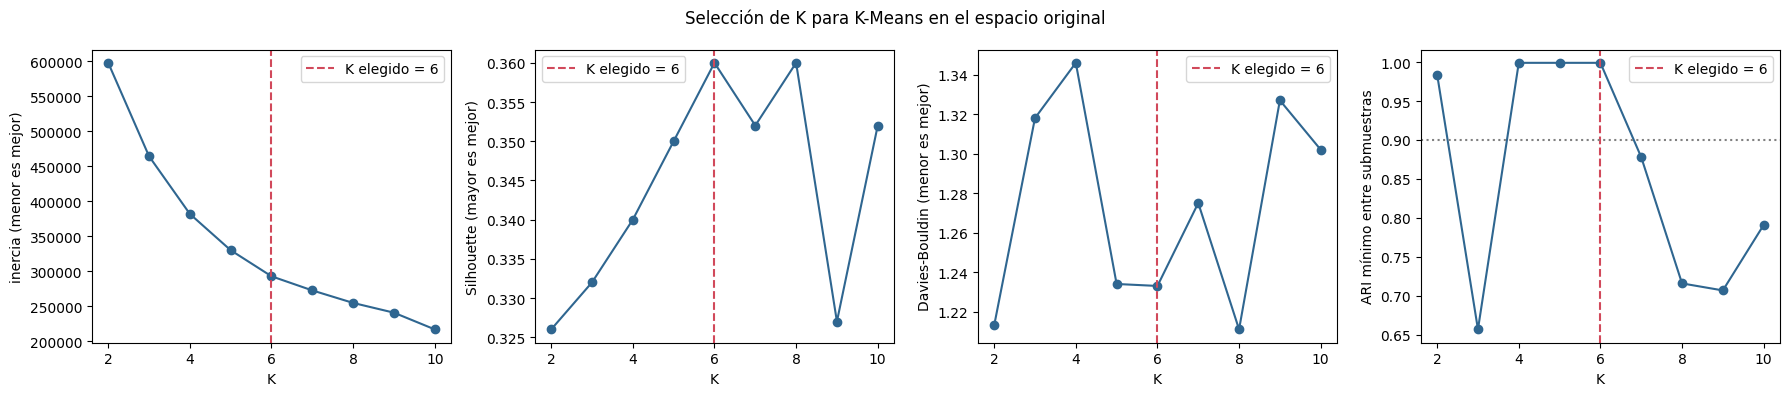

K elegido: 6


,inercia,silhouette,davies_bouldin,calinski_harabasz,estabilidad_media,estabilidad_min,grupo_menor
K,,,,,,,
2,597673,0.326,1.213,3778,0.993,0.984,2447
3,464142,0.332,1.318,3462,0.966,0.657,1647
4,381680,0.340,1.346,3321,1.000,0.999,1456
5,329801,0.350,1.234,3164,1.000,0.999,843
6,292535,0.360,1.233,3035,1.000,0.999,646
7,272349,0.352,1.275,2805,0.966,0.878,646
8,254455,0.360,1.211,2645,0.852,0.716,372
9,240516,0.327,1.327,2500,0.809,0.707,354
10,216630,0.352,1.302,2554,0.916,0.791,372


In [4]:
tabla_km, K_KM = buscar_kmeans(X_tr)
resultados['tabla_km'] = tabla_km.reset_index().to_dict(orient='list')
resultados['k_km'] = K_KM
graficar_kmeans(tabla_km, K_KM, '04_kmeans_seleccion', 'Selección de K para K-Means en el espacio original')
print('K elegido:', K_KM)
tabla_km

Los criterios no coincidieron. Silhouette fue máximo con K igual a 6 y con K igual a 8 (0,360), el codo
de la inercia no tuvo un quiebre claro y Davies-Bouldin fue mínimo con K igual a 8 (1,211), pero con K
igual a 8 la estabilidad mínima cayó a 0,716. Los K estables fueron 2, 4, 5 y 6. K igual a 2 tuvo el
menor Davies-Bouldin de ese grupo (1,213), pero quedó fuera por el mínimo de 4 grupos, porque solo
separaba a los clientes que compran de los 2 447 que solo sacan efectivo. Entre 4, 5 y 6, el menor
Davies-Bouldin fue el de K igual a 6 (1,233), prácticamente empatado con K igual a 5 (1,234). Con K igual
a 6 el Silhouette fue de 0,360 y la estabilidad mínima de 0,999, así que la partición fue casi idéntica
en las diez submuestras.

# Bloque 2: Modelo de mezcla gaussiana (GMM)

GMM supone que cada cliente sale de una de K normales multivariadas y modela la densidad como p(x) = Σ_k
π_k N(x | μ_k, Σ_k), con pesos π_k que suman 1. Ajusta los parámetros con EM. El paso E calcula la
responsabilidad de cada componente sobre cada cliente, γ_ik = π_k N(x_i | μ_k, Σ_k) / Σ_j π_j N(x_i |
μ_j, Σ_j), y el paso M recalcula pesos, medias y covarianzas como promedios ponderados por esas
responsabilidades. Cada iteración sube la log-verosimilitud hasta un máximo local. El método predict
asigna cada cliente al componente de mayor responsabilidad y predict_proba devuelve las
responsabilidades, que usé como probabilidad de pertenencia. K-Means es el caso límite con covarianzas
esféricas iguales y asignaciones duras.

Hay tres hiperparámetros. El parámetro covariance_type fija la forma de cada Σ_k. Con 17 variables, full
estima 153 parámetros por componente, tied 153 compartidos por todos, diag 17 varianzas por componente y
spherical una sola varianza. El parámetro reg_covar suma una constante a la diagonal de cada Σ_k, y aquí
hace falta porque varias variables concentran a muchos clientes en un mismo valor exacto. Sobre ese valor
la varianza estimada tiende a cero y la log-verosimilitud crece sin límite. El número de componentes lo
elegí con el BIC = −2 ln L + p ln n, que castiga la log-verosimilitud L por el número de parámetros p.
Con n_init igual a 5, EM arranca desde cinco inicios y conserva el de mayor verosimilitud.

## Covarianza sin regularizar

Primero ajusté los cuatro tipos de covarianza con K de 2 a 10 y reg_covar igual a 1e-6, el valor por
defecto de scikit-learn, y grafiqué el BIC y el AIC = −2 ln L + 2p. Lo hice para ver qué elegiría un
criterio de verosimilitud por sí solo antes de regularizar. Si el BIC elige bien sin ayuda, la
regularización sobra. Si no, la curva muestra por qué hace falta.

Gráfico guardado: 04_gmm_covarianza.png


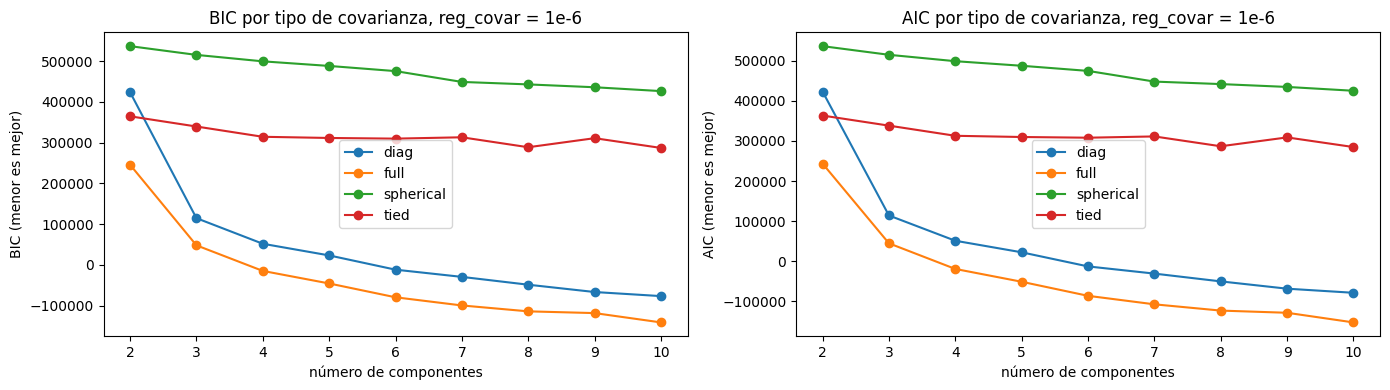

Covarianza con menor BIC sin regularizar: full


covarianza,diag,full,spherical,tied
K,,,,
2,423581,245732,536603,364531
3,114720,48102,515144,339500
4,51958,-14649,499350,314307
5,23374,-45429,488061,311410
6,-11596,-79324,475388,309779
7,-29274,-99346,448848,313084
8,-48463,-113805,442771,288683
9,-66405,-118087,435792,310888
10,-76418,-140931,426354,286974


In [5]:
filas = []
for cov in COVS:
    for k in RANGO:
        g = gmm(k, cov, 1e-6).fit(X_tr)
        filas.append({'covarianza': cov, 'K': k, 'BIC': redondear(g.bic(X_tr), 0), 'AIC': redondear(g.aic(X_tr), 0)})
tabla_cov = pd.DataFrame(filas)
COV_BIC = tabla_cov.groupby('covarianza')['BIC'].min().idxmin()
resultados['tabla_cov'] = tabla_cov.to_dict(orient='list')
resultados['cov_bic'] = COV_BIC

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for cov, g in tabla_cov.groupby('covarianza'):
    ax[0].plot(g['K'], g['BIC'], 'o-', label=cov)
    ax[1].plot(g['K'], g['AIC'], 'o-', label=cov)
for a, t in zip(ax, ['BIC', 'AIC']):
    a.set_xlabel('número de componentes')
    a.set_ylabel(f'{t} (menor es mejor)')
    a.set_title(f'{t} por tipo de covarianza, reg_covar = 1e-6')
    a.legend()
guardar('04_gmm_covarianza')
print('Covarianza con menor BIC sin regularizar:', COV_BIC)
tabla_cov.pivot(index='K', columns='covarianza', values='BIC')

Sin regularización la covarianza full tuvo el menor BIC y el menor AIC en todos los K, y su BIC se volvió
negativo desde K igual a 4 y siguió bajando sin un mínimo. Con la transformación por cuantiles todos los
clientes empatados en el valor mínimo quedan en el mismo punto, menos 5,2, y una componente puede
encogerse sobre ese punto y hacer crecer la verosimilitud sin límite. El criterio estaba premiando
componentes que copian valores repetidos, como el avance en efectivo igual a cero, y no perfiles de
clientes. Por eso no elegí la covarianza solo por BIC.

## Búsqueda con regularización

Después recorrí con buscar_gmm los cuatro tipos de covarianza y seis valores de reg_covar (1e-6, 1e-3,
1e-2, 0,1, 0,3 y 1). El tope de 1 equivale a la varianza de una normal estándar, la escala de salida de
la transformación por cuantiles. Para cada una de las 24 combinaciones, la función calcula la curva de
BIC con K de 2 a 10 y toma K en el codo, el primer K a partir del cual la mejora del BIC al agregar un
componente cae por debajo del 20 por ciento de la mejora de pasar de 2 a 3. Después mide la estabilidad
de esa combinación y aplica la misma regla que en K-Means. Con 9 ajustes por curva más once por la prueba
de estabilidad, es el paso más lento del notebook.

Gráfico guardado: 04_gmm_seleccion.png


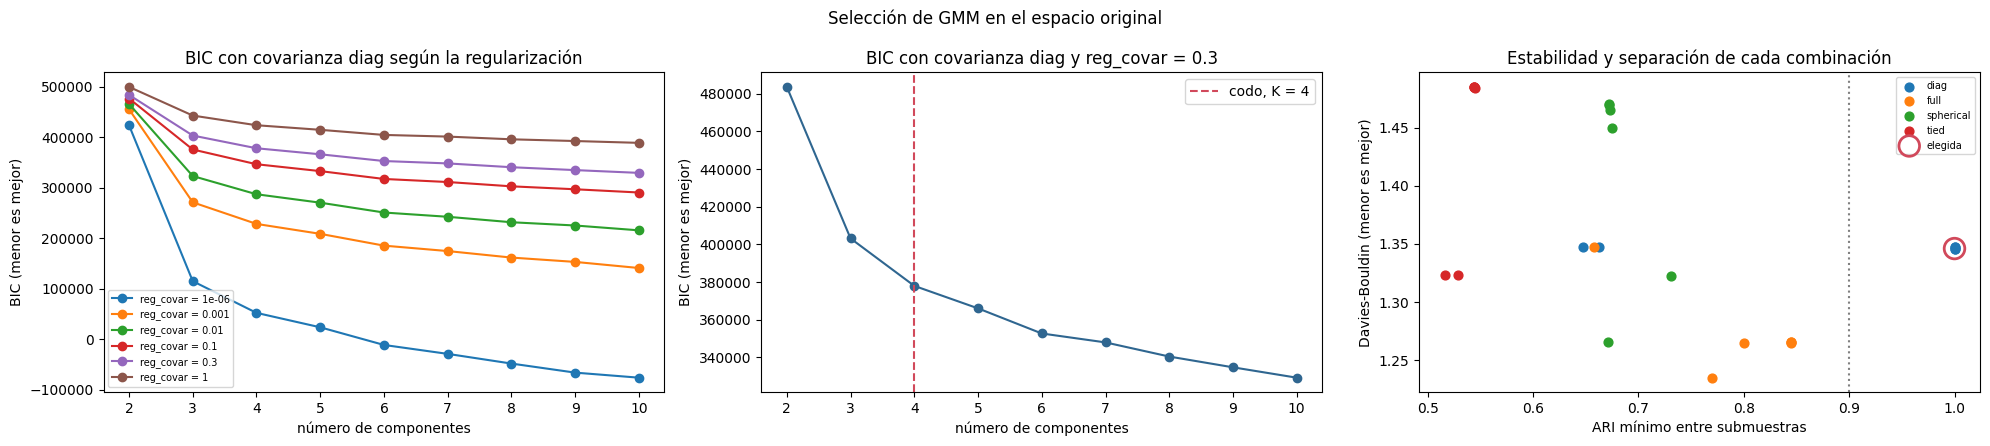

Covarianza: diag | reg_covar: 0.3 | K: 4


,covarianza,reg_covar,K_codo,silhouette,davies_bouldin,calinski_harabasz,estabilidad_media,estabilidad_min,grupo_menor
0,full,0.000001,4,0.339,1.347,3311,0.966,0.658,1447
1,full,0.001000,6,0.359,1.235,3027,0.962,0.770,646
2,full,0.010000,5,0.348,1.266,3083,0.923,0.845,1168
3,full,0.100000,5,0.348,1.266,3083,0.923,0.845,1168
4,full,0.300000,5,0.348,1.265,3088,0.922,0.845,1166
5,full,1.000000,5,0.348,1.265,3088,0.918,0.800,1166
6,tied,0.000001,4,0.317,1.485,2916,0.727,0.544,1486
7,tied,0.001000,4,0.317,1.485,2916,0.727,0.544,1486
8,tied,0.010000,4,0.317,1.485,2916,0.727,0.544,1486
9,tied,0.100000,4,0.317,1.484,2920,0.727,0.545,1486


In [6]:
tabla_gmm, curvas_gmm, COV, REG, K_GMM = buscar_gmm(X_tr)
resultados['tabla_gmm'] = tabla_gmm.to_dict(orient='list')
resultados['cov'], resultados['reg'], resultados['k_gmm'] = COV, REG, K_GMM
graficar_gmm(tabla_gmm, curvas_gmm, COV, REG, K_GMM, '04_gmm_seleccion', 'Selección de GMM en el espacio original')
print('Covarianza:', COV, '| reg_covar:', REG, '| K:', K_GMM)
tabla_gmm

La estabilidad separó con claridad a los tipos de covarianza. Las covarianzas full, tied y spherical
nunca llegaron a la estabilidad mínima de 0,9, con valores entre 0,516 y 0,845. La covarianza diag con
reg_covar de 0,01 o más tuvo una estabilidad mínima de 1,000, con el codo del BIC en K igual a 4 en las
cuatro regularizaciones y un Davies-Bouldin de 1,346 o 1,347. La regla eligió reg_covar igual a 0,3, la
primera de las dos con 1,346, y K igual a 4, con un Silhouette de 0,339. Con reg_covar de 1e-6 y 1e-3 la
misma covarianza diag fue inestable (0,647 y 0,663), porque sin regularización suficiente las varianzas
sobre las masas puntuales se achican hasta casi cero y EM cae en soluciones distintas según el inicio.

La covarianza diag supone que, dentro de cada grupo, las variables varían de forma independiente con su
propia dispersión. Pierde la capacidad de inclinar los grupos, pero conserva lo que distingue a GMM de
K-Means, que son las dispersiones distintas por variable y por grupo y las probabilidades de pertenencia.

# Evaluación en el espacio original

## Efecto de no escalar

Entrené K-Means con el mismo K sobre los datos solo imputados, sin la transformación por cuantiles, y
comparé esa partición con la transformada. También calculé qué parte de la varianza total aporta cada
variable sin escalar, que es el peso que tendría en la distancia euclidiana. La consigna pide mostrar con
los propios datos qué pasa si no se escala, y esta comparación lo mide con los mismos clientes y el mismo
K.

In [7]:
from sklearn.impute import SimpleImputer

imputador = SimpleImputer(strategy='median').fit(X_train)
X_crudo = imputador.transform(X_train)
km_crudo = KMeans(n_clusters=K_KM, n_init=10, random_state=SEMILLA).fit(X_crudo)
km_esc = KMeans(n_clusters=K_KM, n_init=10, random_state=SEMILLA).fit(X_tr)
varianza = pd.Series(X_crudo.var(axis=0), index=X_train.columns)
peso = redondear_serie((varianza / varianza.sum() * 100).sort_values(ascending=False), 1)
sin_escalar = {
    'tamaños_sin_escalar': sorted(np.bincount(km_crudo.labels_).tolist(), reverse=True),
    'tamaños_escalado': sorted(np.bincount(km_esc.labels_).tolist(), reverse=True),
    'silhouette_sin_escalar_en_su_espacio': redondear(silhouette_score(X_crudo, km_crudo.labels_)),
    'silhouette_sin_escalar_en_espacio_escalado': redondear(silhouette_score(X_tr, km_crudo.labels_)),
    'silhouette_escalado': redondear(silhouette_score(X_tr, km_esc.labels_)),
    'ari_entre_particiones': redondear(adjusted_rand_score(km_crudo.labels_, km_esc.labels_)),
    'peso_varianza_top3': peso.head(3).to_dict(),
    'peso_frecuencias': redondear(varianza[frecuencias].sum() / varianza.sum() * 100, 1)}
resultados['sin_escalar'] = sin_escalar
for k, v in sin_escalar.items():
    print(k, v)

tamaños_sin_escalar [4237, 2036, 609, 228, 31, 19]
tamaños_escalado [1647, 1448, 1412, 1164, 843, 646]
silhouette_sin_escalar_en_su_espacio 0.374
silhouette_sin_escalar_en_espacio_escalado -0.059
silhouette_escalado 0.36
ari_entre_particiones 0.033
peso_varianza_top3 {'CREDIT_LIMIT': 30.4, 'PAYMENTS': 18.4, 'MINIMUM_PAYMENTS': 12.9}
peso_frecuencias 0.0


Sin transformar, la variable con más peso fue CREDIT_LIMIT, que concentró el 30,4 por ciento de la
varianza total, seguida por PAYMENTS (18,4 por ciento) y MINIMUM_PAYMENTS (12,9 por ciento). Las seis
variables de frecuencia y proporción sumaron prácticamente cero. El resultado fueron grupos muy
desparejos, de 4 237, 2 036, 609, 228, 31 y 19 clientes, que separaban sobre todo por límite y pagos,
mientras que con la transformación los grupos tuvieron entre 646 y 1 647 clientes.

El Silhouette de esa partición en su propio espacio fue de 0,374, que parece mejor que el 0,360 del
modelo con la transformación. Sin embargo, medido en el espacio transformado bajó a menos 0,059, y el ARI
entre las dos particiones fue de 0,033, es decir que casi no coincidieron. El Silhouette alto sin
transformar solo reflejaba que los montos grandes estaban bien separados entre sí, no que los grupos
describieran el uso de la tarjeta.

## Evaluación de los modelos finales

Entrené los dos modelos con los hiperparámetros elegidos, medí sus tiempos con cronometrar y calculé las
tres métricas en entrenamiento y en prueba. Las etiquetas de prueba salen de predict sin reajustar nada.
En K-Means cada cliente va al centroide más cercano y en GMM al componente de mayor responsabilidad.
Medir en prueba responde si un cliente que el modelo nunca vio cae en un grupo tan claro como los de
entrenamiento, que es lo que pasaría al asignar a los clientes del mes siguiente. Ninguno de los dos
modelos marca puntos como ruido, así que el porcentaje de ruido no aplica.

In [8]:
fab_km = lambda: KMeans(n_clusters=K_KM, n_init=10, random_state=SEMILLA)
fab_gmm = lambda: gmm(K_GMM, COV, REG)
km, t_km, tp_km = cronometrar(fab_km, X_tr, X_te)
gm, t_gm, tp_gm = cronometrar(fab_gmm, X_tr, X_te)
et_km_tr, et_km_te = km.predict(X_tr), km.predict(X_te)
et_gm_tr, et_gm_te = gm.predict(X_tr), gm.predict(X_te)

etapa1 = pd.DataFrame([
    {'modelo': 'K-Means', 'conjunto': 'entrenamiento', **metricas(X_tr, et_km_tr)},
    {'modelo': 'K-Means', 'conjunto': 'prueba', **metricas(X_te, et_km_te)},
    {'modelo': 'GMM', 'conjunto': 'entrenamiento', **metricas(X_tr, et_gm_tr)},
    {'modelo': 'GMM', 'conjunto': 'prueba', **metricas(X_te, et_gm_te)}])
resultados['etapa1'] = etapa1.to_dict(orient='records')
resultados['tamanos_km'] = np.bincount(et_km_tr).tolist()
resultados['tamanos_gmm'] = np.bincount(et_gm_tr).tolist()
resultados['ari_km_vs_gmm'] = redondear(adjusted_rand_score(et_km_tr, et_gm_tr))
print('Tamaños K-Means:', np.bincount(et_km_tr), '| Tamaños GMM:', np.bincount(et_gm_tr))
print('ARI entre K-Means y GMM:', resultados['ari_km_vs_gmm'])
etapa1

Tamaños K-Means: [1412  646 1647 1164  843 1448] | Tamaños GMM: [1645 1448 2255 1812]
ARI entre K-Means y GMM: 0.779


,modelo,conjunto,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,entrenamiento,0.360,1.233,3035
1,K-Means,prueba,0.355,1.223,748
2,GMM,entrenamiento,0.339,1.346,3318
3,GMM,prueba,0.340,1.336,813


K-Means superó a GMM en Silhouette (0,360 contra 0,339) y en Davies-Bouldin (1,233 contra 1,346), y GMM
superó a K-Means en Calinski-Harabasz (3 318 contra 3 035). En prueba las métricas de los dos se
mantuvieron casi iguales a las de entrenamiento (Silhouette de 0,355 y 0,340), lo que indica que los
grupos generalizan a clientes nuevos. El Calinski-Harabasz de prueba es menor porque crece con el número
de puntos, no porque el modelo empeore.

Los dos modelos encontraron la misma estructura a distinta resolución (ARI de 0,779 entre ellos). GMM
juntó en un grupo de 2 255 clientes a los compradores de alto gasto y a los compradores ocasionales en un
pago, que K-Means separó en grupos de 1 412 y 843, y juntó en otro grupo de 1 812 a los clientes que
compran y además retiran efectivo, que K-Means separó en grupos de 1 164 y 646 según cuánto compran.

Con estas cifras elegí K-Means como el mejor modelo del espacio original. Ganó en Silhouette y en
Davies-Bouldin aunque tiene más grupos, separó dos pares de perfiles que piden acciones distintas y sus
centroides se explican directo al área comercial. Las métricas favorecen a los grupos convexos que
construye K-Means, así que la diferencia no prueba por sí sola que GMM describa peor a los clientes, y la
comparación vuelve a hacerse en el espacio reducido del notebook 05.

## Estabilidad

Medí la estabilidad de los dos modelos finales de dos maneras. Entre semillas, reentrené con diez
semillas sobre los mismos clientes, lo que muestra si la inicialización cambia el resultado. Entre
submuestras, usé la función estabilidad, que además cambia los clientes con los que se entrena y muestra
si los grupos dependen de unos pocos clientes particulares. Si los grupos cambiaran al reentrenar, el
banco tendría que rehacer sus campañas cada vez que actualiza el modelo.

In [9]:
est_km = estabilidad(lambda s: KMeans(n_clusters=K_KM, n_init=10, random_state=s), X_tr)
est_gm = estabilidad(lambda s: gmm(K_GMM, COV, REG, s), X_tr)
semillas_km = [adjusted_rand_score(et_km_tr, KMeans(n_clusters=K_KM, n_init=10, random_state=s).fit(X_tr).labels_) for s in range(10)]
semillas_gm = [adjusted_rand_score(et_gm_tr, gmm(K_GMM, COV, REG, s).fit(X_tr).predict(X_tr)) for s in range(10)]
estab = pd.DataFrame({'K-Means': [np.mean(semillas_km), np.min(semillas_km), est_km[0], est_km[1]],
                      'GMM': [np.mean(semillas_gm), np.min(semillas_gm), est_gm[0], est_gm[1]]},
                     index=['ARI medio entre semillas', 'ARI mínimo entre semillas',
                            'ARI medio entre submuestras', 'ARI mínimo entre submuestras']).apply(lambda c: redondear_serie(c))
resultados['estabilidad'] = estab.to_dict()
estab

,K-Means,GMM
ARI medio entre semillas,1.000,1.0
ARI mínimo entre semillas,1.000,1.0
ARI medio entre submuestras,1.000,1.0
ARI mínimo entre submuestras,0.999,1.0


Los dos modelos fueron muy estables. K-Means tuvo un ARI mínimo de 1,000 entre semillas y de 0,999 entre
submuestras, y GMM de 1,000 en los dos casos. Que la semilla no cambie la partición indica que las diez
inicializaciones encuentran siempre la misma solución. Que las submuestras tampoco la cambien indica que
los grupos no dependen de unos pocos clientes particulares.

## Probabilidades de pertenencia y efecto de los atípicos

Tomé la responsabilidad máxima de GMM para cada cliente, conté cuántos quedan por debajo de 0,7 y comparé
la certeza media de los clientes con valores atípicos contra la del resto. También calculé qué porcentaje
de cada grupo, en los dos modelos, tiene algún atípico. Un cliente con probabilidad baja está a medio
camino entre dos perfiles, y para el banco es el que puede cambiar de segmento. Los atípicos, por su
parte, podrían haber formado grupos diminutos que no sirven para una campaña, y quise comprobar si pasó.

pct_dudosos_gmm 0.0
pct_atipicos_por_grupo_km {0: 71.7, 1: 67.6, 2: 58.8, 3: 70.7, 4: 66.4, 5: 68.6}
pct_atipicos_por_grupo_gmm {0: 58.8, 1: 68.6, 2: 69.7, 3: 69.6}
prob_media_atipicos 1.0
prob_media_no_atipicos 1.0


Gráfico guardado: 04_gmm_probabilidades.png


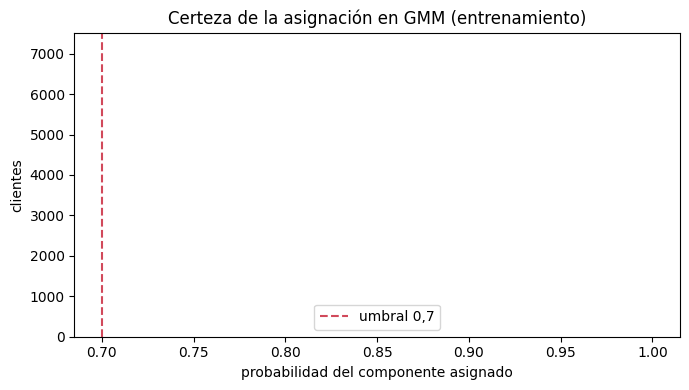

In [10]:
prob = gm.predict_proba(X_tr).max(axis=1)
dudosos = redondear((prob < 0.7).mean() * 100, 1)
atip_tr = fuera.any(axis=1).values
atip = {'pct_dudosos_gmm': dudosos,
        'pct_atipicos_por_grupo_km': redondear_serie(pd.Series(atip_tr).groupby(et_km_tr).mean() * 100, 1).to_dict(),
        'pct_atipicos_por_grupo_gmm': redondear_serie(pd.Series(atip_tr).groupby(et_gm_tr).mean() * 100, 1).to_dict(),
        'prob_media_atipicos': redondear(prob[atip_tr].mean()),
        'prob_media_no_atipicos': redondear(prob[~atip_tr].mean())}
resultados['atipicos_modelos'] = atip
for k, v in atip.items():
    print(k, v)
plt.figure(figsize=(7, 4))
plt.hist(prob, bins=40, color='#2f6690')
plt.axvline(0.7, color='#d1495b', ls='--', label='umbral 0,7')
plt.xlabel('probabilidad del componente asignado')
plt.ylabel('clientes')
plt.title('Certeza de la asignación en GMM (entrenamiento)')
plt.legend()
guardar('04_gmm_probabilidades')

Ningún cliente quedó con una probabilidad menor que 0,7 de pertenecer a su grupo, y la certeza media fue
de 1,000 tanto en los clientes con valores atípicos como en el resto. GMM asignó a todos con certeza casi
total porque, después de la transformación por cuantiles, sus cuatro componentes se apoyan en
combinaciones de masas puntuales, como comprar o no comprar y retirar o no retirar efectivo, y cada
cliente queda muy lejos de las componentes que no le corresponden. En este espacio GMM pierde una de sus
ventajas para el banco, porque no señala a clientes a medio camino entre dos perfiles. Los atípicos no
formaron grupos diminutos. Fueron entre el 58,8 y el 71,7 por ciento de cada grupo en los dos modelos,
cerca del 67,0 por ciento del total, así que quedaron repartidos en todos los perfiles.

## Cierre del notebook

Guardé en etapa1.joblib los hiperparámetros elegidos, las etiquetas de entrenamiento y prueba de los dos
modelos y sus tiempos, para que el notebook 05 los compare con el espacio reducido sin reentrenar.

In [11]:
joblib.dump({'K_KM': K_KM, 'COV': COV, 'REG': REG, 'K_GMM': K_GMM,
             'et_km_tr': et_km_tr, 'et_km_te': et_km_te, 'et_gm_tr': et_gm_tr, 'et_gm_te': et_gm_te,
             't_km': t_km, 'tp_km': tp_km, 't_gm': t_gm, 'tp_gm': tp_gm},
            os.path.join(RUTA, 'etapa1.joblib'))
print('Particiones de la etapa 1 guardadas en etapa1.joblib')
guardar_resultados()

Particiones de la etapa 1 guardadas en etapa1.joblib
Cifras guardadas en resultados.json
